In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [1]:
pip install ucimlrepo

Note: you may need to restart the kernel to use updated packages.


In [2]:
from ucimlrepo import fetch_ucirepo 
  
# fetch dataset 
parkinsons = fetch_ucirepo(id=174) 
  
# data (as pandas dataframes) 
X = parkinsons.data.features 
y = parkinsons.data.targets 
  
# metadata 
print(parkinsons.metadata) 
  
# variable information 
print(parkinsons.variables) 


{'uci_id': 174, 'name': 'Parkinsons', 'repository_url': 'https://archive.ics.uci.edu/dataset/174/parkinsons', 'data_url': 'https://archive.ics.uci.edu/static/public/174/data.csv', 'abstract': "Oxford Parkinson's Disease Detection Dataset", 'area': 'Health and Medicine', 'tasks': ['Classification'], 'characteristics': ['Multivariate'], 'num_instances': 197, 'num_features': 22, 'feature_types': ['Real'], 'demographics': [], 'target_col': ['status'], 'index_col': ['name'], 'has_missing_values': 'no', 'missing_values_symbol': None, 'year_of_dataset_creation': 2007, 'last_updated': 'Wed Feb 14 2024', 'dataset_doi': '10.24432/C59C74', 'creators': ['Max Little'], 'intro_paper': {'ID': 385, 'type': 'NATIVE', 'title': 'Exploiting Nonlinear Recurrence and Fractal Scaling Properties for Voice Disorder Detection', 'authors': 'Max A. Little, P. McSharry, S. Roberts, D. Costello, I. Moroz', 'venue': 'BioMedical Engineering OnLine', 'year': 2007, 'journal': None, 'DOI': '10.1186/1475-925X-6-23', 'URL

In [4]:
import pandas as pd
df =pd.read_csv("https://archive.ics.uci.edu/static/public/174/data.csv")

In [9]:
X.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 195 entries, 0 to 194
Data columns (total 22 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   MDVP:Fo       195 non-null    float64
 1   MDVP:Fhi      195 non-null    float64
 2   MDVP:Flo      195 non-null    float64
 3   MDVP:Jitter   195 non-null    float64
 4   MDVP:Jitter   195 non-null    float64
 5   MDVP:RAP      195 non-null    float64
 6   MDVP:PPQ      195 non-null    float64
 7   Jitter:DDP    195 non-null    float64
 8   MDVP:Shimmer  195 non-null    float64
 9   MDVP:Shimmer  195 non-null    float64
 10  Shimmer:APQ3  195 non-null    float64
 11  Shimmer:APQ5  195 non-null    float64
 12  MDVP:APQ      195 non-null    float64
 13  Shimmer:DDA   195 non-null    float64
 14  NHR           195 non-null    float64
 15  HNR           195 non-null    float64
 16  RPDE          195 non-null    float64
 17  DFA           195 non-null    float64
 18  spread1       195 non-null    

In [20]:
y.value_counts()

status
1         147
0          48
Name: count, dtype: int64

In [34]:
df.columns

Index(['name', 'MDVP:Fo', 'MDVP:Fhi', 'MDVP:Flo', 'MDVP:Jitter',
       'MDVP:Jitter.1', 'MDVP:RAP', 'MDVP:PPQ', 'Jitter:DDP', 'MDVP:Shimmer',
       'MDVP:Shimmer.1', 'Shimmer:APQ3', 'Shimmer:APQ5', 'MDVP:APQ',
       'Shimmer:DDA', 'NHR', 'HNR', 'status', 'RPDE', 'DFA', 'spread1',
       'spread2', 'D2', 'PPE'],
      dtype='object')

In [36]:
import warnings
from lightgbm import LGBMClassifier
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.ensemble import ExtraTreesClassifier, RandomForestClassifier
from sklearn.feature_selection import RFE, SelectFromModel, SelectKBest, f_classif
# Models
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from xgboost import XGBClassifier

warnings.filterwarnings("ignore")



X = df.drop(['status','name'], axis=1)
y = df['status']




X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Training shape: {X_train.shape}, Testing shape: {X_test.shape}")

Training shape: (156, 22), Testing shape: (39, 22)


In [37]:

models = {
    "Logistic Regression": LogisticRegression(random_state=42),
    "SVM (RBF Kernel)": SVC(probability=True, random_state=42),
    "K-Nearest Neighbors": KNeighborsClassifier(n_neighbors=5),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42),
    "Extra Trees": ExtraTreesClassifier(n_estimators=100, random_state=42),
    "XGBoost": XGBClassifier(eval_metric="logloss", random_state=42),
    "LightGBM": LGBMClassifier(
        min_child_samples=5, random_state=42, verbose=-1
    ),
}


results = []


NUM_FEATURES_TO_SELECT = 12

for name, model in models.items():

    
    pipeline = Pipeline(
        [
            ("scaler", StandardScaler()),
            (
                "feature_selection",
                SelectKBest(score_func=f_classif, k=NUM_FEATURES_TO_SELECT),
            ),
            ("classifier", model),
        ]
    )

    
    pipeline.fit(X_train, y_train)

    
    y_pred = pipeline.predict(X_test)
    y_prob = pipeline.predict_proba(X_test)[
        :, 1
    ]  

    
    tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
    specificity = tn / (tn + fp)

    
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    cv_scores = cross_validate(pipeline, X_train, y_train, cv=cv, scoring="f1")

    
    results.append(
        {
            "Model": name,
            "Accuracy": accuracy_score(y_test, y_pred),
            "Precision": precision_score(y_test, y_pred),
            "Recall (Sensitivity)": recall_score(y_test, y_pred),
            "Specificity": specificity,
            "F1-Score": f1_score(y_test, y_pred),
            "ROC-AUC": roc_auc_score(y_test, y_prob),
            "CV F1 (Mean)": np.mean(cv_scores["test_score"]),
        }
    )


results_df = pd.DataFrame(results).sort_values(
    by=["F1-Score", "ROC-AUC"], ascending=False
)
results_df.reset_index(drop=True, inplace=True)


print("\n=== MODEL PERFORMANCE COMPARISON ===")
display(results_df.style.background_gradient(cmap="Blues").format(precision=4))


=== MODEL PERFORMANCE COMPARISON ===


,Model,Accuracy,Precision,Recall (Sensitivity),Specificity,F1-Score,ROC-AUC,CV F1 (Mean)
0,Extra Trees,0.9231,0.9333,0.9655,0.8000,0.9492,0.9276,0.9331
1,Logistic Regression,0.9231,0.9333,0.9655,0.8000,0.9492,0.9207,0.8933
2,K-Nearest Neighbors,0.9231,0.9643,0.9310,0.9000,0.9474,0.9086,0.8973
3,SVM (RBF Kernel),0.8974,0.9032,0.9655,0.7000,0.9333,0.9414,0.8859
4,Random Forest,0.8974,0.9310,0.9310,0.8000,0.9310,0.9397,0.9082
5,XGBoost,0.8718,0.9286,0.8966,0.8000,0.9123,0.9172,0.9075
6,LightGBM,0.8718,0.9286,0.8966,0.8000,0.9123,0.9000,0.9162


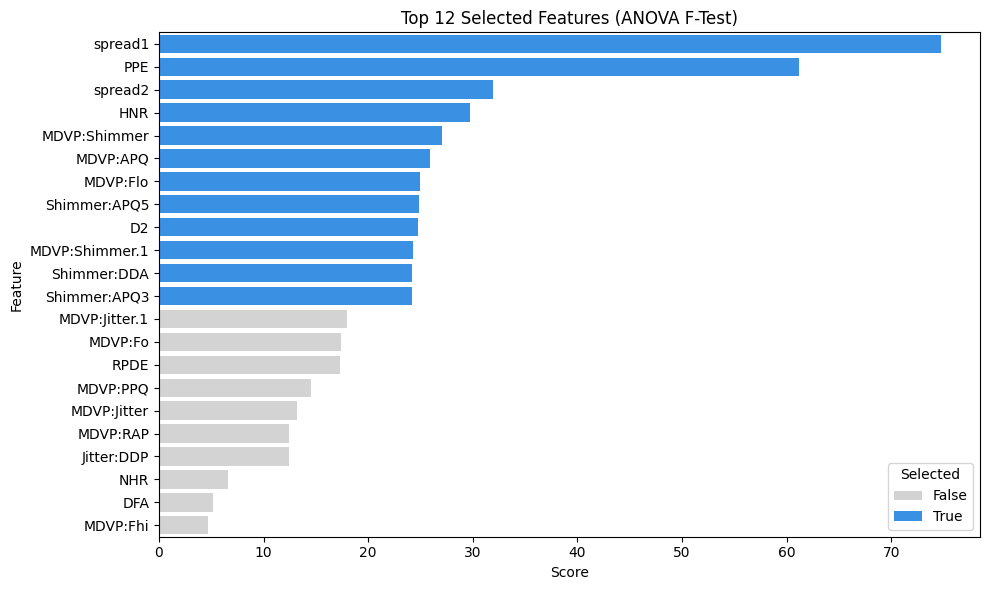

In [39]:

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)

selector = SelectKBest(score_func=f_classif, k=NUM_FEATURES_TO_SELECT)
selector.fit(X_train_scaled, y_train)

selected_features = X.columns[selector.get_support()]
feature_scores = pd.DataFrame(
    {"Feature": X.columns, "Score": selector.scores_, "Selected": selector.get_support()}
).sort_values(by="Score", ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(
    data=feature_scores, x="Score", y="Feature", hue="Selected", dodge=False, palette={True: "dodgerblue", False: "lightgrey"}
)
plt.title(f"Top {NUM_FEATURES_TO_SELECT} Selected Features (ANOVA F-Test)")
plt.tight_layout()
plt.show()

In [40]:
from functools import partial
import warnings
from lightgbm import LGBMClassifier
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.ensemble import ExtraTreesClassifier, RandomForestClassifier
from sklearn.feature_selection import (
    RFE,
    SelectFromModel,
    SelectKBest,
    f_classif,
    mutual_info_classif,
)
# Models
from sklearn.linear_model import LogisticRegression
# Metrics
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    f1_score,
    matthews_corrcoef,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from xgboost import XGBClassifier

warnings.filterwarnings("ignore")




def fix_duplicate_columns(df_features):
    cols = pd.Series(df_features.columns)
    for dup in cols[cols.duplicated()].unique():
        cols[cols[cols == dup].index.values.tolist()] = [
            f"{dup}_{i}" if i != 0 else dup for i in range(sum(cols == dup))
        ]
    df_features = df_features.copy()
    df_features.columns = cols
    return df_features


X = fix_duplicate_columns(X)


X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)


mi_score = partial(mutual_info_classif, random_state=42)

feature_selectors = {
    "ANOVA_Top8": SelectKBest(score_func=f_classif, k=8),
    "ANOVA_Top14": SelectKBest(score_func=f_classif, k=14),
    "Mutual_Info_Top10": SelectKBest(score_func=mi_score, k=10),
    "Lasso_L1": SelectFromModel(
        LogisticRegression(
            penalty="l1", solver="liblinear", C=1.0, random_state=42
        )
    ),
    "RF_Importance": SelectFromModel(
        RandomForestClassifier(n_estimators=100, random_state=42),
        threshold="median",
    ),
    "RFE_ExtraTrees_10": RFE(
        estimator=ExtraTreesClassifier(n_estimators=50, random_state=42),
        n_features_to_select=10,
    ),
    "XGBoost_Embedded": SelectFromModel(
        XGBClassifier(eval_metric="logloss", random_state=42), threshold="mean"
    ),
}


models = {
    "Logistic Regression": LogisticRegression(random_state=42),
    "SVM (RBF)": SVC(probability=True, random_state=42),
    "KNN": KNeighborsClassifier(n_neighbors=5),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42),
    "Extra Trees": ExtraTreesClassifier(n_estimators=100, random_state=42),
    "XGBoost": XGBClassifier(eval_metric="logloss", random_state=42),
    "LightGBM": LGBMClassifier(
        min_child_samples=5, random_state=42, verbose=-1
    ),
}


experiment_results = []
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

for fs_name, selector in feature_selectors.items():
    for model_name, model in models.items():

        
        pipeline = Pipeline(
            [
                ("scaler", StandardScaler()),
                ("selector", selector),
                ("classifier", model),
            ]
        )

        
        pipeline.fit(X_train, y_train)

        
        selected_mask = pipeline.named_steps["selector"].get_support()
        chosen_features = list(X.columns[selected_mask])
        num_features = len(chosen_features)


        y_pred = pipeline.predict(X_test)
        y_prob = pipeline.predict_proba(X_test)[:, 1]

        tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
        specificity = tn / (tn + fp) if (tn + fp) > 0 else 0.0

        
        cv_f1 = cross_val_score(
            pipeline, X_train, y_train, cv=cv, scoring="f1"
        ).mean()

        
        experiment_results.append(
            {
                "Model": model_name,
                "Feature_Selector": fs_name,
                "Num_Features": num_features,
                "Accuracy": accuracy_score(y_test, y_pred),
                "Precision": precision_score(y_test, y_pred, zero_division=0),
                "Recall (Sensitivity)": recall_score(
                    y_test, y_pred, zero_division=0
                ),
                "Specificity": specificity,
                "F1-Score": f1_score(y_test, y_pred, zero_division=0),
                "ROC-AUC": roc_auc_score(y_test, y_prob),
                "MCC": matthews_corrcoef(y_test, y_pred),
                "CV_F1_Mean": cv_f1,
                "Chosen_Features": chosen_features,  
            }
        )


results_df = pd.DataFrame(experiment_results).sort_values(
    by=["F1-Score", "ROC-AUC", "MCC"], ascending=False
)
results_df.reset_index(drop=True, inplace=True)

print(f"Total Experiments Run: {len(results_df)}")

Total Experiments Run: 49


In [41]:

best_per_model = (
    results_df.groupby("Model", as_index=False)
    .first()
    .sort_values(by=["F1-Score", "ROC-AUC"], ascending=False)
    .reset_index(drop=True)
)

print("\n=== BEST CONFIGURATION PER MODEL ===")
display_cols = [
    "Model",
    "Feature_Selector",
    "Num_Features",
    "Accuracy",
    "Precision",
    "Recall (Sensitivity)",
    "Specificity",
    "F1-Score",
    "ROC-AUC",
    "MCC",
]
display(
    best_per_model[display_cols]
    .style.background_gradient(
        cmap="Greens", subset=["F1-Score", "ROC-AUC", "MCC"]
    )
    .format(precision=4)
)


print("\n=== EXACT FEATURES CHOSEN FOR EACH MODEL'S BEST RUN ===")
for idx, row in best_per_model.iterrows():
    print(
        f"🏆 {row['Model']} (via {row['Feature_Selector']} | {row['Num_Features']} features | F1: {row['F1-Score']:.4f} | AUC: {row['ROC-AUC']:.4f})"
    )
    print(f"   Features: {row['Chosen_Features']}\n")


=== BEST CONFIGURATION PER MODEL ===


,Model,Feature_Selector,Num_Features,Accuracy,Precision,Recall (Sensitivity),Specificity,F1-Score,ROC-AUC,MCC
0,SVM (RBF),RFE_ExtraTrees_10,10,0.9487,0.9355,1.0000,0.8000,0.9667,0.9862,0.8651
1,Extra Trees,RFE_ExtraTrees_10,10,0.9487,0.9655,0.9655,0.9000,0.9655,0.9793,0.8655
2,XGBoost,RF_Importance,11,0.9487,0.9655,0.9655,0.9000,0.9655,0.9793,0.8655
3,Random Forest,ANOVA_Top14,14,0.9487,0.9655,0.9655,0.9000,0.9655,0.9638,0.8655
4,Logistic Regression,RFE_ExtraTrees_10,10,0.9231,0.9333,0.9655,0.8000,0.9492,0.9345,0.7934
5,KNN,RFE_ExtraTrees_10,10,0.9231,0.9643,0.9310,0.9000,0.9474,0.9845,0.8064
6,LightGBM,Lasso_L1,9,0.8974,0.9310,0.9310,0.8000,0.9310,0.9655,0.7310



=== EXACT FEATURES CHOSEN FOR EACH MODEL'S BEST RUN ===
🏆 SVM (RBF) (via RFE_ExtraTrees_10 | 10 features | F1: 0.9667 | AUC: 0.9862)
   Features: ['MDVP:Fo', 'MDVP:Flo', 'MDVP:Shimmer', 'HNR', 'RPDE', 'DFA', 'spread1', 'spread2', 'D2', 'PPE']

🏆 Extra Trees (via RFE_ExtraTrees_10 | 10 features | F1: 0.9655 | AUC: 0.9793)
   Features: ['MDVP:Fo', 'MDVP:Flo', 'MDVP:Shimmer', 'HNR', 'RPDE', 'DFA', 'spread1', 'spread2', 'D2', 'PPE']

🏆 XGBoost (via RF_Importance | 11 features | F1: 0.9655 | AUC: 0.9793)
   Features: ['MDVP:Fo', 'MDVP:Fhi', 'MDVP:Flo', 'MDVP:RAP', 'Jitter:DDP', 'Shimmer:APQ5', 'NHR', 'spread1', 'spread2', 'D2', 'PPE']

🏆 Random Forest (via ANOVA_Top14 | 14 features | F1: 0.9655 | AUC: 0.9638)
   Features: ['MDVP:Fo', 'MDVP:Flo', 'MDVP:Jitter.1', 'MDVP:Shimmer', 'MDVP:Shimmer.1', 'Shimmer:APQ3', 'Shimmer:APQ5', 'MDVP:APQ', 'Shimmer:DDA', 'HNR', 'spread1', 'spread2', 'D2', 'PPE']

🏆 Logistic Regression (via RFE_ExtraTrees_10 | 10 features | F1: 0.9492 | AUC: 0.9345)
   Featu

In [42]:
# Save full experiment log (Metrics + Chosen Features)
results_df_export = results_df.copy()
# Convert the list of features to a comma-separated string for clean CSV/Excel viewing
results_df_export["Chosen_Features"] = results_df_export[
    "Chosen_Features"
].apply(lambda x: ", ".join(x))
results_df_export.to_csv("parkinsons_model_feature_experiments.csv", index=False)
print("Saved all results and chosen features to 'parkinsons_model_feature_experiments.csv'")

Saved all results and chosen features to 'parkinsons_model_feature_experiments.csv'


In [44]:
import joblib
import numpy as np
import pandas as pd
from sklearn.ensemble import ExtraTreesClassifier, VotingClassifier
from sklearn.metrics import classification_report, roc_auc_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

# 1. Lock in the 10 winning features discovered by your experiment
WINNING_FEATURES = [
    "MDVP:Fo",
    "MDVP:Flo",
    "MDVP:Shimmer",
    "HNR",
    "RPDE",
    "DFA",
    "spread1",
    "spread2",
    "D2",
    "PPE",
]

# Filter your training and testing data to ONLY use these 10 features
X_train_final = X_train[WINNING_FEATURES]
X_test_final = X_test[WINNING_FEATURES]

# 2. Define the Top Models
svm_model = SVC(kernel="rbf", probability=True, random_state=42)
et_model = ExtraTreesClassifier(n_estimators=100, random_state=42)

# Optional: Combine your #1 (SVM) and #2 (Extra Trees) into an Ensemble
# Since both use the exact same 10 features!
ensemble_model = VotingClassifier(
    estimators=[("svm", svm_model), ("et", et_model)], voting="soft"
)

# 3. Build the Production Pipeline (Scaler + Model)
# You can swap 'svm_model' with 'et_model' or 'ensemble_model' here
production_pipeline = Pipeline(
    [
        ("scaler", StandardScaler()),
        ("classifier", svm_model),  # Using your #1 Ranked Model: SVM (RBF)
    ]
)

# 4. Verify on Test Set one last time
production_pipeline.fit(X_train_final, y_train)
y_pred = production_pipeline.predict(X_test_final)
y_prob = production_pipeline.predict_proba(X_test_final)[:, 1]

print("=== FINAL MODEL TEST VERIFICATION ===")
print(
    classification_report(
        y_test, y_pred, target_names=["Healthy (0)", "Parkinson's (1)"]
    )
)
print(f"Test ROC-AUC: {roc_auc_score(y_test, y_prob):.4f}\n")

# 5. FIT ON 100% OF THE DATA FOR DEPLOYMENT & SAVE
# (Best practice: once validated, train on all 195 rows so the deployed model has maximum knowledge)
X_full_final = X[WINNING_FEATURES]
production_pipeline.fit(X_full_final, y)

# Save both the pipeline and the required feature list
model_artifact = {
    "pipeline": production_pipeline,
    "features": WINNING_FEATURES,
    "model_name": "SVM (RBF) - 10 Features",
}

joblib.dump(model_artifact, "parkinsons_inference_model.joblib")
print("✅ Successfully saved model to 'parkinsons_inference_model.joblib'")

=== FINAL MODEL TEST VERIFICATION ===
                 precision    recall  f1-score   support

    Healthy (0)       1.00      0.80      0.89        10
Parkinson's (1)       0.94      1.00      0.97        29

       accuracy                           0.95        39
      macro avg       0.97      0.90      0.93        39
   weighted avg       0.95      0.95      0.95        39

Test ROC-AUC: 0.9862

✅ Successfully saved model to 'parkinsons_inference_model.joblib'


In [45]:
import joblib
import pandas as pd

# 1. Load the saved model artifact
artifact = joblib.load("parkinsons_inference_model.joblib")
pipeline = artifact["pipeline"]
required_features = artifact["features"]


def predict_parkinsons(patient_data: dict, threshold: float = 0.5):
    """Predicts Parkinson's status for a single patient.

    Args:
        patient_data (dict): Dictionary containing the 10 acoustic features.
        threshold (float): Probability cutoff (Default 0.5).

    Returns:
        dict: Prediction result, label, and confidence probability.
    """
    # Convert input dictionary to a DataFrame with the exact feature order
    df_input = pd.DataFrame([patient_data])[required_features]

    # Get probability of Parkinson's (Class 1)
    prob_parkinsons = pipeline.predict_proba(df_input)[0, 1]

    # Apply threshold
    prediction = int(prob_parkinsons >= threshold)
    diagnosis = (
        "Parkinson's Detected (1)" if prediction == 1 else "Healthy Control (0)"
    )

    return {
        "prediction": prediction,
        "diagnosis": diagnosis,
        "parkinsons_probability": round(float(prob_parkinsons) * 100, 2),
        "healthy_probability": round((1 - float(prob_parkinsons)) * 100, 2),
    }


# =====================================================================
# EXAMPLE USAGE: Testing on a New Patient
# =====================================================================
new_patient = {
    "MDVP:Fo": 119.992,  # Average vocal fundamental frequency
    "MDVP:Flo": 74.997,  # Minimum vocal fundamental frequency
    "MDVP:Shimmer": 0.04374,  # Variation in amplitude
    "HNR": 21.033,  # Harmonics-to-noise ratio
    "RPDE": 0.414783,  # Recurrence period density entropy
    "DFA": 0.815285,  # Detrended fluctuation analysis
    "spread1": -4.813031,  # Nonlinear measure of fundamental frequency variation
    "spread2": 0.266482,  # Nonlinear measure of fundamental frequency variation
    "D2": 2.301442,  # Correlation dimension
    "PPE": 0.284654,  # Pitch period entropy
}

result = predict_parkinsons(new_patient)

print("=== INFERENCE RESULT ===")
print(f"Diagnosis              : {result['diagnosis']}")
print(f"Parkinson's Probability: {result['parkinsons_probability']}%")
print(f"Healthy Probability    : {result['healthy_probability']}%")

=== INFERENCE RESULT ===
Diagnosis              : Parkinson's Detected (1)
Parkinson's Probability: 96.93%
Healthy Probability    : 3.07%
